
__author__ = "C.Doussot"
__date__ =  18-February-2025

# Questionnaire analysis  Fig. 4-C&F

Strategy rankings and self-assessed successful scale. Requires Participants_details.csv.

In [1]:
# Data handling
import os
import re
import csv
import warnings
import itertools as it

import numpy as np
import pandas as pd
from tqdm import tqdm

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import cm
from matplotlib.colors import Normalize
from matplotlib.patches import FancyArrowPatch

# Networks and statistical tests
import networkx as nx
from scipy.stats import binomtest, chi2_contingency, chisquare
import statsmodels.stats.multitest as stm

# Functions stored in a1_helpers.py
from a1_helpers import (
    get_time_taken_sec,
    extract_strategies,
    get_percentages,
    parse_values,
    directed_to_undirected_with_summed_weights,
    graph_primer,
    create_dic,
    percentage_scaler,
    get_transition_df,
    Euclidean_Dist,
)

# Progress bars for pandas
tqdm.pandas()

# Hide deprecation warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)

In [2]:
from pathlib import Path

# Run with the notebook's Analysis folder as the working directory.
assert Path('a1_helpers.py').is_file(), 'Set the working directory to the Analysis folder.'
fig_folder = '../Figure_paper/'
Path(fig_folder).mkdir(parents=True, exist_ok=True)
colors = ['#0033ff', '#ff4ff1']

In [3]:
sequence_df = pd.read_csv('../Combined_data/seq_df_2025.csv', index_col=0)
sequence_df['game'] = sequence_df['experiment'].str[-1]

In [4]:
# Load the questionnaire data processed by G_results_questionnaire.
participants_details = pd.read_csv(
    '../Combined_data/Participants_details.csv',
    index_col=0,
)

# Remove records without a participant ID.
participants_details = participants_details.dropna(subset=['ppid'])

# Add one questionnaire record to each participant's sequence rows.
sequence_df = sequence_df.merge(
    participants_details,
    on='ppid',
    how='left',
    validate='many_to_one',
    indicator=True,
)

# Report participants whose questionnaire data are missing.
missing = sequence_df.loc[
    sequence_df['_merge'] == 'left_only', 'ppid'
].unique()

print("Participants without questionnaire data:", missing.tolist())

sequence_df = sequence_df.drop(columns='_merge')

Participants without questionnaire data: ['Dolmen', 'Morne']


Review note: survey answers are repeated across condition/scale groups. The >100 threshold and frequency-ordered strategy labels are retained from A1 and require review before interpreting the figure.

In [5]:
# Extract only first row from ppid*cond*scale because values are repeated for each data point. 
survey_results_df = sequence_df.groupby(['ppid','cond','scale']).first().reset_index()

In [6]:
survey_results_df[['t1_strat', 't2_strat', 't3_strat']] = survey_results_df['most_strat'].apply(lambda x: pd.Series(extract_strategies(x)))

Error processing row, invalid answer: None -> 'NoneType' object has no attribute 'split'
Error processing row, invalid answer: None -> 'NoneType' object has no attribute 'split'
Error processing row, invalid answer: None -> 'NoneType' object has no attribute 'split'
Error processing row, invalid answer: None -> 'NoneType' object has no attribute 'split'
Error processing row, invalid answer: None -> 'NoneType' object has no attribute 'split'
Error processing row, invalid answer: None -> 'NoneType' object has no attribute 'split'
Error processing row, invalid answer: None -> 'NoneType' object has no attribute 'split'
Error processing row, invalid answer: None -> 'NoneType' object has no attribute 'split'
Error processing row, invalid answer: None -> 'NoneType' object has no attribute 'split'
Error processing row, invalid answer: None -> 'NoneType' object has no attribute 'split'
Error processing row, invalid answer: None -> 'NoneType' object has no attribute 'split'
Error processing row,

In [7]:
forplot = survey_results_df.loc[:,['t1_strat', 't2_strat', 't3_strat']]

In [8]:
# Count occurrences of each strategy in each column : 
counts = pd.concat([forplot[col].value_counts() for col in ['t1_strat', 't2_strat', 't3_strat']], axis=1).fillna(0)
column_names = ['Top_1', 'Top_2', 'Top_3']
# Rename columns for readability
counts.columns = column_names

# Compute total appearances of each strategy
counts['Total'] = counts.sum(axis=1)
counts  =  counts.sort_values("Total", ascending=False)

# keep only if used more than 100 
counts = counts.loc[counts.Total > 100]

### Figure 4F

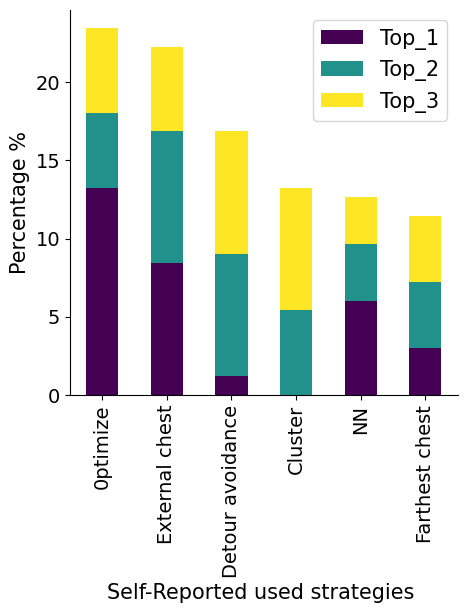

In [9]:
# Convert Top 1, Top 2, and Top 3 counts into proportions within the strategy's total count
counts_pct_with_total = counts[column_names].div(counts['Total'], axis=0)

# Multiply by the total percentage each strategy represents in all rankings
counts_pct_with_total = counts_pct_with_total.multiply(counts['Total'] / counts['Total'].sum() * 100, axis=0)
counts_pct_with_total['new_index'] = np.array(['0ptimize','External chest','Detour avoidance','Cluster','NN','Farthest chest'])
counts_pct_with_total = counts_pct_with_total.reset_index().set_index('new_index')

# Plot the stacked bar chart where bar height = total percentage, and segments show proportions
fig, ax = plt.subplots(figsize=(5, 5))
counts_pct_with_total.plot(kind='bar', stacked=True, ax=ax, colormap='viridis')

plt.ylabel("Percentage %",fontsize = 15)
plt.xticks(rotation=90)
plt.xlabel("Self-Reported used strategies ",fontsize = 15)
plt.legend(title="Rank", bbox_to_anchor=(0.8, 1), loc='upper left')
sns.despine()
ax.legend(fontsize = 15)
ax.tick_params(axis='both', which='major', labelsize=14)
ax.tick_params(axis='both', which='minor', labelsize=10)
#plt.savefig(fig_folder+'Fig_Prefstrat.png',bbox_inches='tight',dpi =300)
#plt.savefig(fig_folder+'Fig_Prefstrat.svg',bbox_inches='tight')
plt.show()

In [10]:
# participants were not aware of actual size but only relative ones during the survey 
# change to actual tested scale for each game group

# correspondance survey and tested
map_A = {'small': 'XS',  'medium': 'M', 'large': 'XL'}
map_B = {'small': 'S',  'medium': 'M', 'large': 'L'}

sequence_df['new_best_scale'] = np.select(
    [
        (sequence_df['game'] == 'A') & (sequence_df['best_estimated_scale'].isin(map_A)),
        (sequence_df['game'] == 'B') & (sequence_df['best_estimated_scale'].isin(map_B)),
        (sequence_df['best_estimated_scale'] == 'medium')
    ],
    [
        sequence_df['best_estimated_scale'].map(map_A),
        sequence_df['best_estimated_scale'].map(map_B),
        'M'
    ],
    default=np.nan
)

# Verify no old labels remain
invalid_labels = {'small', 'large', 'medium'}
remaining = set(sequence_df['new_best_scale'].dropna().unique()) & invalid_labels

assert not remaining, f"Unexpected leftover labels in new_best_scale: {remaining}"

In [11]:
toplot = sequence_df.groupby(['ppid','cond','scale']).first().reset_index()

res = toplot.groupby(['game']).new_best_scale.value_counts().to_frame().reset_index().rename(columns={"count":"total"})

res.loc[:,['percentage']] = res.groupby('game')['total'].apply(get_percentages).reset_index(level=0, drop=True)

(0.0, 100.0)

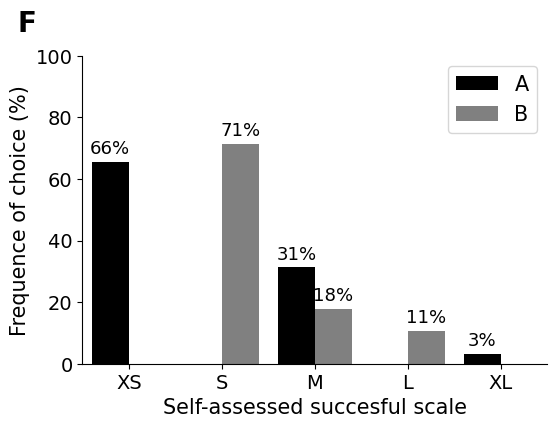

In [12]:
# Plot
fig, ax = plt.subplots(figsize=(6, 4))
order =['XS','S','M','L','XL']
res['new_best_scale'] = pd.Categorical(res['new_best_scale'], categories = order, ordered=True)

ax = sns.barplot(x="new_best_scale", y = 'percentage',data=res, palette=['black','grey'],hue='game',dodge = True)
sns.despine()
ax.set_xlabel('Self-assessed succesful scale',fontsize = 15)
ax.set_ylabel('Frequence of choice (%)',fontsize = 15)
for c in ax.containers:
    # percentage on top of bars
    ax.bar_label(c, fmt='%.0f%%', padding=3, fontsize=13, color='black')

ax.text(-0.1, 1.15, 'F', transform=ax.transAxes,
    fontsize=20, fontweight='bold', va='top', ha='right')
ax.legend(fontsize = 15)
ax.tick_params(axis='both', which='major', labelsize=14)
ax.tick_params(axis='both', which='minor', labelsize=10)
ax.set_ylim(0,100)
#plt.savefig(fig_folder+'Fig_Prefscalef.png',bbox_inches='tight')
#plt.savefig(fig_folder+'Fig_Prefscalef.svg',bbox_inches='tight')